In [2]:
from email import utils
import polars as pl
import pandas as pd
import geopandas as gpd
from shapely.geometry import Polygon, MultiPolygon, Point
import matplotlib.pyplot as plt
from pathlib import Path
import sys
import re
from tqdm import tqdm
sys.path.append("../src")  # Add path to where 'retail' package lives
import retail.retailfilter as rf # Correct import path
import retail.retailfilter_new as rfn
import utils.utils as ut  # Correct import path


def polars_to_geoparquet(
    pl_df: pl.DataFrame,
    out_path: str,
    lat_col: str = "lat",
    lng_col: str = "lng",
    crs: str = "EPSG:4326",
):
    pdf = pl_df.to_pandas()
    gdf = gpd.GeoDataFrame(
        pdf,
        geometry=gpd.points_from_xy(pdf[lng_col], pdf[lat_col]),
        crs=crs,
    )
    gdf.to_parquet(out_path, index=False)


[nltk_data] Downloading package names to /home/ogoodwin/nltk_data...
[nltk_data]   Package names is already up-to-date!


In [3]:

# Input file
# input_file = Path("../data/input_files/uk_foursquare_datefields_admin_categories.parquet")
input_file = Path("../data/input_files/uk_foursquare_cc_aug.parquet")
# Read in parquet
foursquare = pl.read_parquet(input_file)
print(len(foursquare))
# Filter
foursquare_filtnew = rfn.filter_foursquare(foursquare)

unique_levels = (
    foursquare_filtnew
    .group_by("level1_category_name", "level2_category_name", "level3_category_name")
    .len()
    .rename({"len": "count"})
    .sort("count", descending=True)
)

unique_levels.write_csv("../data/POI_files/foursquare_unique_levels.csv")
print(len(foursquare_filtnew))



# Columns to keep
COLUMNS_TO_KEEP = [
    "fsq_place_id", "name", "lat", "lng","fsq_category_labels", "address", "locality", "region",
    "postcode", "admin_region", "post_town", 
    "date_created", "date_refreshed", "date_closed", "tel", "website", 
    "fsq_category_ids", "h3_11","level1_category_name", "level2_category_name", "level3_category_name",
]

# name has changed now its exploded.
if "fsq_category_ids" in foursquare_filtnew.columns:
    COLUMNS_TO_KEEP_MOD = [col if col != "fsq_category_id" else "fsq_category_ids" for col in COLUMNS_TO_KEEP]
elif "fsq_category_id" in foursquare_filtnew.columns:
    COLUMNS_TO_KEEP_MOD = [col if col != "fsq_category_ids" else "fsq_category_id" for col in COLUMNS_TO_KEEP]
else:
    COLUMNS_TO_KEEP_MOD = COLUMNS_TO_KEEP

# Add H3 column
foursquare_filtnew = ut.add_h3_11_column(foursquare_filtnew)

# Keep only selected columns
foursquare_filtnew = foursquare_filtnew.select(COLUMNS_TO_KEEP_MOD)





4685463
Filtered Foursquare data (Retail Cats): 1931072 rows remaining.
Filtered Foursquare data (remove post box): 1931019 rows remaining.
Filtered Foursquare data (remove closed): 1672307 rows remaining.
1503284


In [ ]:

# --- Load roads once ---
roads = gpd.read_file("uk_roads.gpkg", layer="roads")
print(f"Roads loaded: {len(roads)}")

# --- Convert roads once ---
roads = roads.to_crs(epsg=27700)
print(f"Roads loaded: {len(roads)}")


Roads loaded: 7776570
Roads loaded: 7776570


Processing POIs: 100%|██████████| 1503284/1503284 [01:31<00:00, 16486.36rows/s, rows 1,500,000–1,503,284]


SchemaError: type String is incompatible with expected type List(String)

In [4]:
# --- Function to process a single chunk ---
def process_chunk(df_chunk: pl.DataFrame, roads: gpd.GeoDataFrame, buffer_dist: float) -> gpd.GeoDataFrame:
    # Convert Polars -> Pandas -> GeoPandas
    pdf = df_chunk.to_pandas()
    gdf = gpd.GeoDataFrame(
        pdf,
        geometry=gpd.points_from_xy(pdf["lng"], pdf["lat"]),
        crs="EPSG:4326"
    ).to_crs(epsg=27700)

    nearest = gpd.sjoin_nearest(
        gdf, roads, how="left", distance_col="dist_to_road"
    )

    # Keep only POIs further than buffer_dist
    return nearest[nearest["dist_to_road"] > buffer_dist]

# --- Parameters ---
buffer_dist = 250       # distance in meters
chunk_size = 100_000   # adjust based on your memory
# --- Loop through Foursquare in chunks ---
results = []
n_rows = foursquare_filtnew.height

with tqdm(total=n_rows, desc="Processing POIs", unit="rows") as pbar:
    for start in range(0, n_rows, chunk_size):
        end = min(start + chunk_size, n_rows)
        pbar.set_postfix_str(f"rows {start:,}–{end:,}")
        chunk = foursquare_filtnew.slice(start, end - start)
        chunk_result = process_chunk(chunk, roads, buffer_dist)
        results.append(chunk_result)
        pbar.update(end - start)

# --- Concatenate all chunks back together (GeoPandas) ---
if results:
    foursquare_far = gpd.GeoDataFrame(
        pd.concat(results, ignore_index=True), crs=results[0].crs
    )
else:
    foursquare_far = gpd.GeoDataFrame()

print("\nSummary:")
print(" Original POIs:", n_rows)
print(f" Further than {buffer_dist}m:", len(foursquare_far))


Processing POIs:   0%|          | 0/1503284 [00:00<?, ?rows/s, rows 0–100,000]


NameError: name 'roads' is not defined

In [ ]:
import geopandas as gpd
import pandas as pd

#100 m buffer most of what it removes are real pois but just mislocated slightly off cost, even so these arent useful
# --- Convert Polars -> Pandas -> GeoDataFrame ---
pdf = foursquare_filtnew.to_pandas()
foursquare_gdf = gpd.GeoDataFrame(
    pdf,
    geometry=gpd.points_from_xy(pdf["lng"], pdf["lat"]),
    crs="EPSG:4326"
).to_crs(epsg=27700)

# --- Load UK boundary (from your .gpkg file) ---
uk_boundary = gpd.read_file(
    "../data/input_files/Countries_December_2022_UK_BGC_1943732719298389253.gpkg"
).to_crs(epsg=27700)

# Dissolve into a single polygon
uk_boundary = uk_boundary.dissolve()

# Add 100m buffer
uk_boundary["geometry"] = uk_boundary.buffer(100)

# --- Spatial join: keep POIs that intersect buffered boundary ---
joined = gpd.sjoin(
    foursquare_gdf, uk_boundary, how="left", predicate="within"
)

# POIs with no boundary match = outside UK (+100m buffer)
outside_uk = joined[joined.index_right.isna()]

print("Total POIs:", len(foursquare_gdf))
print("Outside UK boundary (100m buffer):", len(outside_uk))


Total POIs: 1503284
Outside UK boundary (100m buffer): 351


In [10]:
outside_uk.to_parquet("../data/POI_files/foursquare_outside_uk.parquet", index=False)

In [3]:
malls = foursquare_filtnew.filter(
    pl.col("fsq_category_id").is_in(["5744ccdfe4b0c0459246b4dc", "4bf58dd8d48988d1fd941735"])
)

print(len(malls))
malls_unique = malls.unique(subset=["fsq_place_id"])


3043


In [32]:
# --- helpers from earlier (unchanged) ---
def _norm_text(s: str) -> str:
    if s is None:
        return ""
    s = s.lower()
    s = re.sub(r"[^\w\s]", " ", s)
    s = re.sub(r"\s+", " ", s).strip()
    return s

def _norm_site(s: str) -> str:
    if not s:
        return ""
    s = s.lower().strip()
    s = re.sub(r"^https?://(www\.)?", "", s)
    s = s.rstrip("/")
    return s

def _levenshtein(a: str, b: str) -> int:
    if a == b: return 0
    if not a: return len(b)
    if not b: return len(a)
    if len(a) > len(b): a, b = b, a
    prev = list(range(len(a) + 1))
    for j, cb in enumerate(b, start=1):
        curr = [j]
        for i, ca in enumerate(a, start=1):
            curr.append(min(prev[i] + 1, curr[i - 1] + 1, prev[i - 1] + (ca != cb)))
        prev = curr
    return prev[-1]

def _lev_ratio(a: str, b: str) -> float:
    la, lb = len(a), len(b)
    if la == 0 and lb == 0:
        return 0.0
    return 1.0 - (_levenshtein(a, b) / max(la, lb))

name_threshold = 0.5

# ---- base df: add row_id only once ----
df = foursquare_filtnew
if "row_id" not in df.columns:
    df = df.with_row_index("row_id")

# ---- rounded keys at 6 dp ----
dfn = (
    df.with_columns(
        pl.col("lat").cast(pl.Float64).round(6).alias("lat_round"),
        pl.col("lng").cast(pl.Float64).round(6).alias("lng_round"),
        pl.col("name").map_elements(_norm_text,return_dtype=str).alias("name_norm"),
        pl.col("address").map_elements(_norm_text,return_dtype=str).alias("address_norm"),
        pl.col("tel").map_elements(_norm_text,return_dtype=str).alias("tel_norm"),
        pl.col("website").map_elements(_norm_site,return_dtype=str).alias("website_norm"),
    )
)

# use rounded coords in the duplicate key
keys = ["lat_round", "lng_round", "fsq_category_id"]

pairs = (
    dfn.join(dfn, on=keys, how="inner", suffix="_r")
       .filter(pl.col("row_id") < pl.col("row_id_r"))
       .with_columns(
           (pl.col("address_norm") == pl.col("address_norm_r")).alias("m_address"),
           (pl.col("tel_norm") == pl.col("tel_norm_r")).alias("m_tel"),
           (pl.col("website_norm") == pl.col("website_norm_r")).alias("m_website"),
           pl.struct(["name_norm","name_norm_r"])
             .map_elements(lambda s: _lev_ratio(s["name_norm"], s["name_norm_r"]), return_dtype=pl.Float64)
             .alias("name_sim"),
       )
       .with_columns((pl.col("name_sim") >= name_threshold).alias("m_name"))
       .with_columns(
           (pl.col("m_address") | pl.col("m_tel") | pl.col("m_website") | pl.col("m_name")).alias("is_match")
       )
       .filter(pl.col("is_match"))
       .with_columns(
           pl.concat_list([
               pl.when(pl.col("m_address")).then(pl.lit("address")).otherwise(None),
               pl.when(pl.col("m_tel")).then(pl.lit("tel")).otherwise(None),
               pl.when(pl.col("m_website")).then(pl.lit("website")).otherwise(None),
               pl.when(pl.col("m_name")).then(pl.lit("name")).otherwise(None),
           ]).alias("match_list_raw")
       )
       .with_columns(pl.col("match_list_raw").list.drop_nulls().alias("match_list"))
       .select("row_id", "row_id_r", *keys, "match_list")
)

# implicated row_ids
implicated_ids = (
    pl.concat([
        pairs.select(pl.col("row_id").alias("row_id")),
        pairs.select(pl.col("row_id_r").alias("row_id")),
    ])
    .unique()
)

# per-row union of matched fields
row_match_fields = (
    pl.concat([
        pairs.select("row_id", "match_list").rename({"row_id": "rid"}),
        pairs.select(pl.col("row_id_r").alias("rid"), "match_list"),
    ])
    .group_by("rid")
    .agg(pl.col("match_list").flatten().alias("match_fields_list"))
    .with_columns(
        pl.col("match_fields_list").list.unique().list.sort().list.join(", ").alias("match_fields")
    )
    .select(pl.col("rid").alias("row_id"), "match_fields")
)

# add dup_count per rounded-key group and keep groups together, largest first
dupes_grouped = (
    dfn.join(implicated_ids, on="row_id", how="inner")   # <-- use dfn (has lat_round/lng_round)
      .join(
          implicated_ids.join(dfn.select("row_id", *keys), on="row_id", how="inner")  # <-- dfn here too
                        .group_by(keys).agg(pl.len().alias("dup_count")),
          on=keys, how="left"
      )
      .join(row_match_fields, on="row_id", how="left")
      .sort(["dup_count"] + keys, descending=[True, False, False, False])
)

dupes_grouped


row_id,fsq_place_id,name,lat,lng,fsq_category_labels,address,locality,region,postcode,admin_region,post_town,date_created,date_refreshed,date_closed,tel,website,fsq_category_id,h3_11,level1_category_name,level2_category_name,level3_category_name,lat_round,lng_round,name_norm,address_norm,tel_norm,website_norm,dup_count,match_fields
u32,str,str,f64,f64,list[str],str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,u32,str
359863,"""687e98791ac14e63ad34b851""","""Locksmith Services in Chelsea …",51.52433,-0.174952,"[""Business and Professional Services > Locksmith""]","""18 Cooper House""","""London""","""Greater London""","""NW8 8NJ""","""England""","""London""","""2022-01-08""","""2022-01-08""",null,"""020 3667 3601""","""https://locksmiths.ltd/chelsea…","""52f2ab2ebcbc57f1066b8b1e""","""8b195da48782fff""","""Business and Professional Serv…","""Locksmith""",null,51.52433,-0.174952,"""locksmith services in chelsea …","""18 cooper house""","""020 3667 3601""","""locksmiths.ltd/chelsea-locksmi…",63,"""address, name, tel"""
1041761,"""2e4b560cc1114483602b2f57""","""24/7 Locksmith Services in Pri…",51.52433,-0.174952,"[""Business and Professional Services > Locksmith""]","""18 Cooper House""","""London""","""Greater London""","""NW8 8NJ""","""England""","""London""","""2022-01-19""","""2022-01-19""",null,"""020 3667 3601""","""https://locksmiths.ltd/primros…","""52f2ab2ebcbc57f1066b8b1e""","""8b195da48795fff""","""Business and Professional Serv…","""Locksmith""",null,51.52433,-0.174952,"""24 7 locksmith services in pri…","""18 cooper house""","""020 3667 3601""","""locksmiths.ltd/primrose-hill-l…",63,"""address, name, tel"""
600259,"""906f84fceb584ae83d84c5fe""","""24/7 Locksmith Services in Bre…",51.52433,-0.174952,"[""Business and Professional Services > Locksmith""]","""18 Cooper House""","""London""","""Greater London""","""NW8 8NJ""","""England""","""London""","""2022-01-22""","""2022-01-22""",null,"""020 3667 3601""","""https://locksmiths.ltd/kilburn…","""52f2ab2ebcbc57f1066b8b1e""","""8b195da48795fff""","""Business and Professional Serv…","""Locksmith""",null,51.52433,-0.174952,"""24 7 locksmith services in bre…","""18 cooper house""","""020 3667 3601""","""locksmiths.ltd/kilburn-locksmi…",63,"""address, name, tel, website"""
156194,"""594c5752519a42dbc4f9f5cf""","""Locksmiths Barnes SW13""",51.52433,-0.174952,"[""Business and Professional Services > Locksmith""]","""18 Cooper House""","""London""","""Greater London""","""NW8 8NJ""","""England""","""London""","""2022-01-17""","""2022-01-17""",null,"""020 3667 3601""","""https://locksmiths.ltd/barnes-…","""52f2ab2ebcbc57f1066b8b1e""","""8b195da48795fff""","""Business and Professional Serv…","""Locksmith""",null,51.52433,-0.174952,"""locksmiths barnes sw13""","""18 cooper house""","""020 3667 3601""","""locksmiths.ltd/barnes-locksmit…",63,"""address, name, tel"""
156193,"""563e4d6ee58a4d24581215b8""","""24/7 Locksmith Services in Sou…",51.52433,-0.174952,"[""Business and Professional Services > Locksmith""]","""18 Cooper House""","""London""","""Greater London""","""NW8 8NJ""","""England""","""London""","""2022-01-23""","""2022-01-23""",null,"""020 3667 3601""","""https://locksmiths.ltd/south-w…","""52f2ab2ebcbc57f1066b8b1e""","""8b195da48782fff""","""Business and Professional Serv…","""Locksmith""",null,51.52433,-0.174952,"""24 7 locksmith services in sou…","""18 cooper house""","""020 3667 3601""","""locksmiths.ltd/south-wimbledon…",63,"""address, name, tel, website"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
266613,"""5589bb1462f048a19cc773f3""","""Post Office""",58.933693,-3.28967,"[""Community and Government > Government Building > Post Office""]","""1 Hoy High""","""Stromness""","""Orkney""","""KW16 3NG""","""Scotland""","""Stromness""","""2021-11-11""","""2021-11-11""",null,"""0345 611 2970""","""http://www.postoffice.co.uk""","""4bf58dd8d48988d172941735""","""8b19281a6c6efff""","""Community and Government""","""Gove

In [26]:
# --- helpers from earlier (unchanged) ---
def _norm_text(s: str) -> str:
    if s is None:
        return ""
    s = s.lower()
    s = re.sub(r"[^\w\s]", " ", s)
    s = re.sub(r"\s+", " ", s).strip()
    return s

def _norm_site(s: str) -> str:
    if not s:
        return ""
    s = s.lower().strip()
    s = re.sub(r"^https?://(www\.)?", "", s)
    s = s.rstrip("/")
    return s

def _levenshtein(a: str, b: str) -> int:
    if a == b: return 0
    if not a: return len(b)
    if not b: return len(a)
    if len(a) > len(b): a, b = b, a
    prev = list(range(len(a) + 1))
    for j, cb in enumerate(b, start=1):
        curr = [j]
        for i, ca in enumerate(a, start=1):
            curr.append(min(prev[i] + 1, curr[i - 1] + 1, prev[i - 1] + (ca != cb)))
        prev = curr
    return prev[-1]

def _lev_ratio(a: str, b: str) -> float:
    la, lb = len(a), len(b)
    if la == 0 and lb == 0:
        return 0.0
    return 1.0 - (_levenshtein(a, b) / max(la, lb))

name_threshold = 0.5

# ---- base df: add row_id only once ----
df = foursquare_filtnew
if "row_id" not in df.columns:
    df = df.with_row_index("row_id")

# ---- rounded keys at 6 dp ----
dfn = (
    df.with_columns(
        pl.col("lat").cast(pl.Float64).round(6).alias("lat_round"),
        pl.col("lng").cast(pl.Float64).round(6).alias("lng_round"),
        pl.col("name").map_elements(_norm_text, return_dtype=str).alias("name_norm"),
        pl.col("address").map_elements(_norm_text, return_dtype=str).alias("address_norm"),  # kept for reference, not used in matching
        pl.col("tel").map_elements(_norm_text, return_dtype=str).alias("tel_norm"),
        pl.col("website").map_elements(_norm_site, return_dtype=str).alias("website_norm"),
    )
)

# use rounded coords in the duplicate key
keys = ["lat_round", "lng_round", "fsq_category_id"]

pairs = (
    dfn.join(dfn, on=keys, how="inner", suffix="_r")
       .filter(pl.col("row_id") < pl.col("row_id_r"))
       .with_columns(
           # REMOVED: address equality check from matching logic
           (pl.col("tel_norm") == pl.col("tel_norm_r")).alias("m_tel"),
           (pl.col("website_norm") == pl.col("website_norm_r")).alias("m_website"),
           pl.struct(["name_norm","name_norm_r"])
             .map_elements(lambda s: _lev_ratio(s["name_norm"], s["name_norm_r"]), return_dtype=pl.Float64)
             .alias("name_sim"),
       )
       .with_columns((pl.col("name_sim") >= name_threshold).alias("m_name"))
       .with_columns(
           # is_match now only considers tel, website, and name similarity
           (pl.col("m_tel") | pl.col("m_website") | pl.col("m_name")).alias("is_match")
       )
       .filter(pl.col("is_match"))
       .with_columns(
           # match list excludes 'address'
           pl.concat_list([
               pl.when(pl.col("m_tel")).then(pl.lit("tel")).otherwise(None),
               pl.when(pl.col("m_website")).then(pl.lit("website")).otherwise(None),
               pl.when(pl.col("m_name")).then(pl.lit("name")).otherwise(None),
           ]).alias("match_list_raw")
       )
       .with_columns(pl.col("match_list_raw").list.drop_nulls().alias("match_list"))
       .select("row_id", "row_id_r", *keys, "match_list")
)

# implicated row_ids
implicated_ids = (
    pl.concat([
        pairs.select(pl.col("row_id").alias("row_id")),
        pairs.select(pl.col("row_id_r").alias("row_id")),
    ])
    .unique()
)

# per-row union of matched fields
row_match_fields = (
    pl.concat([
        pairs.select("row_id", "match_list").rename({"row_id": "rid"}),
        pairs.select(pl.col("row_id_r").alias("rid"), "match_list"),
    ])
    .group_by("rid")
    .agg(pl.col("match_list").flatten().alias("match_fields_list"))
    .with_columns(
        pl.col("match_fields_list").list.unique().list.sort().list.join(", ").alias("match_fields")
    )
    .select(pl.col("rid").alias("row_id"), "match_fields")
)

# add dup_count per rounded-key group and keep groups together, largest first
dupes_grouped_no_add = (
    dfn.join(implicated_ids, on="row_id", how="inner")
      .join(
          implicated_ids.join(dfn.select("row_id", *keys), on="row_id", how="inner")
                        .group_by(keys).agg(pl.len().alias("dup_count")),
          on=keys, how="left"
      )
      .join(row_match_fields, on="row_id", how="left")
      .sort(["dup_count"] + keys, descending=[True, False, False, False])
)

dupes_grouped_no_add


row_id,fsq_place_id,name,lat,lng,fsq_category_labels,address,locality,region,postcode,admin_region,post_town,date_created,date_refreshed,date_closed,tel,website,fsq_category_id,h3_11,level1_category_name,level2_category_name,level3_category_name,lat_round,lng_round,name_norm,address_norm,tel_norm,website_norm,dup_count,match_fields
u32,str,str,f64,f64,list[str],str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,u32,str
897488,"""216284ab1ecb4ef213db9c85""","""Locksmiths Tooting SW17""",51.52433,-0.174952,"[""Business and Professional Services > Locksmith""]","""18 Cooper House""","""London""","""Greater London""","""NW8 8NJ""","""England""","""London""","""2022-01-16""","""2022-01-16""",null,"""020 3667 3601""","""https://locksmiths.ltd/tooting…","""52f2ab2ebcbc57f1066b8b1e""","""8b195da48795fff""","""Business and Professional Serv…","""Locksmith""",null,51.52433,-0.174952,"""locksmiths tooting sw17""","""18 cooper house""","""020 3667 3601""","""locksmiths.ltd/tooting-locksmi…",63,"""name, tel"""
323845,"""0adadb54976641665df89cdb""","""Locksmiths Wimbledon SW19""",51.52433,-0.174952,"[""Business and Professional Services > Locksmith""]","""18 Cooper House""","""London""","""Greater London""","""NW8 8NJ""","""England""","""London""","""2022-01-16""","""2022-01-16""",null,"""020 3667 3601""","""https://locksmiths.ltd/wimbled…","""52f2ab2ebcbc57f1066b8b1e""","""8b195da48782fff""","""Business and Professional Serv…","""Locksmith""",null,51.52433,-0.174952,"""locksmiths wimbledon sw19""","""18 cooper house""","""020 3667 3601""","""locksmiths.ltd/wimbledon-locks…",63,"""name, tel"""
1292779,"""8cb576680ead4f3957088363""","""Locksmith Services in Willesde…",51.52433,-0.174952,"[""Business and Professional Services > Locksmith""]","""18 Cooper House""","""London""","""Greater London""","""NW8 8NJ""","""England""","""London""","""2022-01-16""","""2022-01-16""",null,"""020 3667 3601""","""https://locksmiths.ltd/willesd…","""52f2ab2ebcbc57f1066b8b1e""","""8b195da48782fff""","""Business and Professional Serv…","""Locksmith""",null,51.52433,-0.174952,"""locksmith services in willesde…","""18 cooper house""","""020 3667 3601""","""locksmiths.ltd/willesden-locks…",63,"""name, tel"""
1121622,"""9d65802edb66451910f56080""","""24/7 Locksmith Services in Bat…",51.52433,-0.174952,"[""Business and Professional Services > Locksmith""]","""18 Cooper House""","""London""","""Greater London""","""NW8 8NJ""","""England""","""London""","""2022-01-22""","""2022-01-22""",null,"""020 3667 3601""","""https://locksmiths.ltd/batters…","""52f2ab2ebcbc57f1066b8b1e""","""8b195da48795fff""","""Business and Professional Serv…","""Locksmith""",null,51.52433,-0.174952,"""24 7 locksmith services in bat…","""18 cooper house""","""020 3667 3601""","""locksmiths.ltd/battersea-locks…",63,"""name, tel, website"""
374790,"""1bd96add00fd4a599428d6bb""","""Locksmith Services in Hendon N…",51.52433,-0.174952,"[""Business and Professional Services > Locksmith""]","""18 Cooper House""","""London""","""Greater London""","""NW8 8NJ""","""England""","""London""","""2022-01-16""","""2022-01-16""",null,"""020 3667 3601""","""https://locksmiths.ltd/hendon-…","""52f2ab2ebcbc57f1066b8b1e""","""8b195da48782fff""","""Business and Professional Serv…","""Locksmith""",null,51.52433,-0.174952,"""locksmith services in hendon n…","""18 cooper house""","""020 3667 3601""","""locksmiths.ltd/hendon-locksmit…",63,"""name, tel"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
266613,"""5589bb1462f048a19cc773f3""","""Post Office""",58.933693,-3.28967,"[""Community and Government > Government Building > Post Office""]","""1 Hoy High""","""Stromness""","""Orkney""","""KW16 3NG""","""Scotland""","""Stromness""","""2021-11-11""","""2021-11-11""",null,"""0345 611 2970""","""http://www.postoffice.co.uk""","""4bf58dd8d48988d172941735""","""8b19281a6c6efff""","""Community and Government""","""Government Building""","""Post Office""",58.933693,-3.28967,"""

In [33]:
diff = dupes_grouped.join(
    dupes_grouped_no_add,
    on="fsq_place_id",
    how="anti"
)


In [34]:
diff

row_id,fsq_place_id,name,lat,lng,fsq_category_labels,address,locality,region,postcode,admin_region,post_town,date_created,date_refreshed,date_closed,tel,website,fsq_category_id,h3_11,level1_category_name,level2_category_name,level3_category_name,lat_round,lng_round,name_norm,address_norm,tel_norm,website_norm,dup_count,match_fields
u32,str,str,f64,f64,list[str],str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,u32,str
377192,"""28510f5b076c4a37312b7ff5""","""HP ePrint Setup""",57.180641,-2.152922,"[""Retail > Print Store""]","""14502 North Dale Mabry Highway…",null,null,null,null,null,"""2022-01-14""","""2022-01-14""",null,"""07824 859307""","""https://www.hpeprint.us""","""52f2ab2ebcbc57f1066b8b28""","""8b19768ccd8cfff""","""Retail""","""Print Store""",null,57.180641,-2.152922,"""hp eprint setup""","""14502 north dale mabry highway…","""07824 859307""","""hpeprint.us""",29,"""address"""
1125512,"""87052211599c47b92ee09383""","""Canon imageCLASS Mf644cdw Wire…",57.180641,-2.152922,"[""Business and Professional Services > Legal Service"", ""Retail > Print Store""]","""14502 North Dale Mabry Highway…",null,null,null,null,null,"""2021-12-31""","""2021-12-31""",null,"""0844 898 6210""","""https://www.all-printer-setup.…","""52f2ab2ebcbc57f1066b8b28""","""8b19768ccd8cfff""","""Retail""","""Print Store""",null,57.180641,-2.152922,"""canon imageclass mf644cdw wire…","""14502 north dale mabry highway…","""0844 898 6210""","""all-printer-setup.com/canon-im…",29,"""address"""
1271838,"""8451d6560b754035932844ce""","""HP OfficeJet pro 8615 driver d…",57.180641,-2.152922,"[""Retail > Print Store""]","""14502 North Dale Mabry Highway…",null,null,null,null,null,"""2021-12-29""","""2021-12-29""",null,"""0844 788 0600""","""https://www.b123-hp.com/123-hp…","""52f2ab2ebcbc57f1066b8b28""","""8b19768ccd8cfff""","""Retail""","""Print Store""",null,57.180641,-2.152922,"""hp officejet pro 8615 driver d…","""14502 north dale mabry highway…","""0844 788 0600""","""b123-hp.com/123-hp-com-ojpro86…",29,"""address"""
205827,"""fc844c43920f40b9881d7676""","""Amine to Amine Crosslinker""",56.127508,-3.138937,"[""Sports and Recreation > Gym and Studio""]","""45-1 Ramsey Rd""","""Shirley""","""Derbyshire""",null,"""England""",null,"""2022-01-03""","""2022-01-03""",null,"""056 1430 9018""","""https://www.cd-bioparticles.co…","""4bf58dd8d48988d175941735""","""8b197201d260fff""","""Sports and Recreation""","""Gym and Studio""",null,56.127508,-3.138937,"""amine to amine crosslinker""","""45 1 ramsey rd""","""056 1430 9018""","""cd-bioparticles.com/p/absolut-…",23,"""address"""
110937,"""6e388c1188614b0c0e5435aa""","""PARP Family""",56.127508,-3.138937,"[""Sports and Recreation > Gym and Studio""]","""45-1 Ramsey Rd""","""Shirley""","""Derbyshire""",null,"""England""",null,"""2022-01-07""","""2022-01-07""",null,"""01922 610015""","""https://www.creative-biogene.c…","""4bf58dd8d48988d175941735""","""8b197201d260fff""","""Sports and Recreation""","""Gym and Studio""",null,56.127508,-3.138937,"""parp family""","""45 1 ramsey rd""","""01922 610015""","""creative-biogene.com/support/p…",23,"""address"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
1392441,"""d6f4346fbdb743fcf95452fc""","""Blythswood K""",57.67723,-2.961985,"[""Retail""]","""28-30 East Church St""","""Buckie""","""Banffshire""","""AB56 1AB""","""Scotland""","""Buckie""","""2019-08-10""","""2019-08-10""",null,"""01542 839700""","""https://www.blythswood.org""","""4d4b7105d754a06378d81259""","""8b192ba51c85fff""","""Retail""",null,null,57.67723,-2.961985,"""blythswood k""","""28 30 east church st""","""01542 839700""","""blythswood.org""",2,"""address"""
1475255,"""014b87ddb488463462f8df0e""","""Mairi Urquhart & Son Funeral G…",57.695553,-4.256118,"[""Business and Professional Services > Funeral Home""]","""Mitchell Lane Unit 1-3""","""Alness""","""Ross-Shire""","""IV17 0QW""","""Scotland""","""Alness""","""2021-11-12""","""2025-06-12""",null,"""01349 

In [23]:
import math
import polars as pl
import h3  # pip install h3

EARTH_R_M = 6_371_000.0
dist_thresh = 15
# --- helpers from earlier (unchanged) ---
def _norm_text(s: str) -> str:
    if s is None:
        return ""
    s = s.lower()
    s = re.sub(r"[^\w\s]", " ", s)
    s = re.sub(r"\s+", " ", s).strip()
    return s

def _norm_site(s: str) -> str:
    if not s:
        return ""
    s = s.lower().strip()
    s = re.sub(r"^https?://(www\.)?", "", s)
    s = s.rstrip("/")
    return s

def _levenshtein(a: str, b: str) -> int:
    if a == b: return 0
    if not a: return len(b)
    if not b: return len(a)
    if len(a) > len(b): a, b = b, a
    prev = list(range(len(a) + 1))
    for j, cb in enumerate(b, start=1):
        curr = [j]
        for i, ca in enumerate(a, start=1):
            curr.append(min(prev[i] + 1, curr[i - 1] + 1, prev[i - 1] + (ca != cb)))
        prev = curr
    return prev[-1]

def _lev_ratio(a: str, b: str) -> float:
    la, lb = len(a), len(b)
    if la == 0 and lb == 0:
        return 0.0
    return 1.0 - (_levenshtein(a, b) / max(la, lb))

def _haversine_m(lat1, lon1, lat2, lon2) -> float:
    # Accurate enough for 5 m cutoff
    phi1 = math.radians(lat1)
    phi2 = math.radians(lat2)
    dphi = phi2 - phi1
    dlmb = math.radians(lon2 - lon1)
    a = math.sin(dphi/2)**2 + math.cos(phi1)*math.cos(phi2)*math.sin(dlmb/2)**2
    return 2 * EARTH_R_M * math.asin(math.sqrt(a))

name_threshold = 0.5

# ---- base df: add row_id only once ----
df = foursquare_filtnew
if "row_id" not in df.columns:
    df = df.with_row_index("row_id")

# ---- normalized text/site columns (keep originals for distance) ----
dfn = (
    df.with_columns(
        pl.col("lat").cast(pl.Float64),
        pl.col("lng").cast(pl.Float64),
        pl.col("name").map_elements(_norm_text, return_dtype=str).alias("name_norm"),
        pl.col("address").map_elements(_norm_text, return_dtype=str).alias("address_norm"),
        pl.col("tel").map_elements(_norm_text, return_dtype=str).alias("tel_norm"),
        pl.col("website").map_elements(_norm_site, return_dtype=str).alias("website_norm"),
    )
    # keep only the columns we will need going forward to save memory
    .select([
        "row_id", "lat", "lng", "h3_11", "fsq_category_id",
        "name_norm", "address_norm", "tel_norm", "website_norm"
    ])
)

# ---- cell -> neighbors (k=1 ring) mapping (includes the cell itself) ----
# Build once based on the unique cells present
unique_cells = dfn.select("h3_11").unique()

neighbors = (
    unique_cells
    .with_columns(
        pl.col("h3_11")
          .map_elements(lambda h: list(h3.grid_disk(h, 1)), return_dtype=pl.List(pl.Utf8))
          .alias("cand_cells")
    )
    .explode("cand_cells")
    .rename({"h3_11": "src_cell", "cand_cells": "cand_cell"})
)

# ---- Expand each row to its 7 candidate cells (self + 6 neighbors) ----
dfn_exp = (
    dfn.join(neighbors, left_on="h3_11", right_on="src_cell", how="inner")
       .select([
           "row_id", "lat", "lng", "h3_11", "fsq_category_id",
           "name_norm", "address_norm", "tel_norm", "website_norm",
           "cand_cell"
       ])
)

pairs_raw = (
    dfn_exp.join(
        dfn,
        left_on=["cand_cell", "fsq_category_id"],
        right_on=["h3_11", "fsq_category_id"],
        how="inner",
        suffix="_r",
    )
    .with_columns(pl.col("cand_cell").alias("h3_11_r"))   # <-- add this
    .filter(pl.col("row_id") < pl.col("row_id_r"))
)


# ---- (cheap) pre-filter by tiny bbox to trim far pairs before exact distance (optional but helpful) ----
# Using conservative bounds so we don't drop true 5m matches.
pairs_pre = pairs_raw.filter(
    ((pl.col("lat") - pl.col("lat_r")).abs() <= 1) &   # ~<= 16-17 m in latitude
    ((pl.col("lng") - pl.col("lng_r")).abs() <= 1)      # generous in longitude to be safe across latitudes
)

# ---- Exact distance (Haversine) + original similarity logic ----
pairs = (
    pairs_pre
    .with_columns(
        pl.struct(["lat","lng","lat_r","lng_r"])
          .map_elements(lambda s: _haversine_m(s["lat"], s["lng"], s["lat_r"], s["lng_r"]), return_dtype=pl.Float64)
          .alias("dist_m"),
        (pl.col("address_norm") == pl.col("address_norm_r")).alias("m_address"),
        (pl.col("tel_norm") == pl.col("tel_norm_r")).alias("m_tel"),
        (pl.col("website_norm") == pl.col("website_norm_r")).alias("m_website"),
        pl.struct(["name_norm","name_norm_r"])
          .map_elements(lambda s: _lev_ratio(s["name_norm"], s["name_norm_r"]), return_dtype=pl.Float64)
          .alias("name_sim"),
    )
    .with_columns((pl.col("name_sim") >= name_threshold).alias("m_name"))
    # Now require BOTH: within 5 m AND (any of the other fields match)
    .with_columns(
        ((pl.col("dist_m") <= dist_thresh) & (pl.col("m_address") | pl.col("m_tel") | pl.col("m_website") | pl.col("m_name")))
        .alias("is_match")
    )
    .filter(pl.col("is_match"))
    .with_columns(
        pl.concat_list([
            pl.when(pl.col("m_address")).then(pl.lit("address")).otherwise(None),
            pl.when(pl.col("m_tel")).then(pl.lit("tel")).otherwise(None),
            pl.when(pl.col("m_website")).then(pl.lit("website")).otherwise(None),
            pl.when(pl.col("m_name")).then(pl.lit("name")).otherwise(None),
            pl.when(pl.col("dist_m") < dist_thresh).then(pl.lit("≤5m")).otherwise(None),
        ]).alias("match_list_raw")
    )
    .with_columns(pl.col("match_list_raw").list.drop_nulls().alias("match_list"))
    .select(
        "row_id", "row_id_r",
        "h3_11", pl.col("h3_11_r"),
        "fsq_category_id",
        "dist_m",
        "match_list"
    )
)

# ---- implicated row_ids ----
implicated_ids = pl.concat([
    pairs.select(pl.col("row_id").alias("row_id")),
    pairs.select(pl.col("row_id_r").alias("row_id")),
]).unique()

# ---- per-row union of matched fields ----
row_match_fields = (
    pl.concat([
        pairs.select("row_id", "match_list").rename({"row_id": "rid"}),
        pairs.select(pl.col("row_id_r").alias("rid"), "match_list"),
    ])
    .group_by("rid")
    .agg(pl.col("match_list").flatten().alias("match_fields_list"))
    .with_columns(
        pl.col("match_fields_list").list.unique().list.sort().list.join(", ").alias("match_fields")
    )
    .select(pl.col("rid").alias("row_id"), "match_fields")
)

# ---- per-row match degree (how many within-5m matches this row has) ----
dup_degree = (
    pl.concat([
        pairs.select(pl.col("row_id").alias("rid")),
        pairs.select(pl.col("row_id_r").alias("rid")),
    ])
    .group_by("rid")
    .agg((pl.len() + 1).alias("dup_count"))
    .rename({"rid": "row_id"})
)

# ---- final rows, sorted by how "duplicate-y" they are ----
dupes_grouped = (
    dfn.join(implicated_ids, on="row_id", how="inner")
       .join(dup_degree, on="row_id", how="left")
       .join(row_match_fields, on="row_id", how="left")
       .sort(["dup_count", "h3_11"], descending=[True, False])
)

dupes_grouped


row_id,lat,lng,h3_11,fsq_category_id,name_norm,address_norm,tel_norm,website_norm,dup_count,match_fields
u32,f64,f64,str,str,str,str,str,str,u32,str
1211973,51.52433,-0.174952,"""8b195da48782fff""","""52f2ab2ebcbc57f1066b8b1e""","""locksmith services in belsize …","""18 cooper house""","""020 3667 3601""","""locksmiths.ltd/hampstead-locks…",63,"""address, name, tel, website, ≤…"
374790,51.52433,-0.174952,"""8b195da48782fff""","""52f2ab2ebcbc57f1066b8b1e""","""locksmith services in hendon n…","""18 cooper house""","""020 3667 3601""","""locksmiths.ltd/hendon-locksmit…",63,"""address, name, tel, ≤5m"""
34769,51.52433,-0.174952,"""8b195da48782fff""","""52f2ab2ebcbc57f1066b8b1e""","""locksmiths merton sw19""","""18 cooper house""","""020 3667 3601""","""locksmiths.ltd/merton-locksmit…",63,"""address, name, tel, ≤5m"""
900425,51.52433,-0.174952,"""8b195da48782fff""","""52f2ab2ebcbc57f1066b8b1e""","""locksmiths norbury sw16""","""18 cooper house""","""020 3667 3601""","""locksmiths.ltd/norbury-locksmi…",63,"""address, name, tel, ≤5m"""
264247,51.52433,-0.174952,"""8b195da48782fff""","""52f2ab2ebcbc57f1066b8b1e""","""westminster locksmiths""","""18 cooper house""","""020 3667 3601""","""locksmiths.ltd/south-wimbledon…",63,"""address, tel, website, ≤5m"""
…,…,…,…,…,…,…,…,…,…,…
327869,57.307473,-2.626802,"""8b1976c40628fff""","""4bf58dd8d48988d128951735""","""ingrained inc""","""the smiddy""","""07507 555218""",null,2,"""address, tel, ≤5m"""
330052,57.444712,-3.127037,"""8b1976c94351fff""","""4bf58dd8d48988d11b951735""","""floral occasions""","""15 fife st""","""01340 820567""","""dufftownfloraloccasions.co.uk""",2,"""tel, ≤5m"""
1066599,57.444704,-3.127252,"""8b1976c94353fff""","""4bf58dd8d48988d11b951735""","""rustic roses""","""7 fife st""","""01340 820567""","""rustic-and-roses.co.uk""",2,"""tel, ≤5m"""


In [ ]:

# #run with level 2 
# # use rounded coords in the duplicate key
# keys = ["lat_round", "lng_round", "level2_category_name"]

# pairs = (
#     dfn.join(dfn, on=keys, how="inner", suffix="_r")
#        .filter(pl.col("row_id") < pl.col("row_id_r"))
#        # exclude pairs with identical fsq_category_id
#        .filter(pl.col("fsq_category_id") != pl.col("fsq_category_id_r"))
#        .with_columns(
#            (pl.col("address_norm") == pl.col("address_norm_r")).alias("m_address"),
#            (pl.col("tel_norm") == pl.col("tel_norm_r")).alias("m_tel"),
#            (pl.col("website_norm") == pl.col("website_norm_r")).alias("m_website"),
#            pl.struct(["name_norm","name_norm_r"])
#              .map_elements(lambda s: _lev_ratio(s["name_norm"], s["name_norm_r"]))
#              .alias("name_sim"),
#        )
#        .with_columns((pl.col("name_sim") >= name_threshold).alias("m_name"))
#        .with_columns(
#            (pl.col("m_address") | pl.col("m_tel") | pl.col("m_website") | pl.col("m_name")).alias("is_match")
#        )
#        .filter(pl.col("is_match"))
#        .with_columns(
#            pl.concat_list([
#                pl.when(pl.col("m_address")).then(pl.lit("address")).otherwise(None),
#                pl.when(pl.col("m_tel")).then(pl.lit("tel")).otherwise(None),
#                pl.when(pl.col("m_website")).then(pl.lit("website")).otherwise(None),
#                pl.when(pl.col("m_name")).then(pl.lit("name")).otherwise(None),
#            ]).alias("match_list_raw")
#        )
#        .with_columns(pl.col("match_list_raw").list.drop_nulls().alias("match_list"))
#        .select("row_id", "row_id_r", *keys, "match_list")
# )

# # implicated row_ids
# implicated_ids = (
#     pl.concat([
#         pairs.select(pl.col("row_id").alias("row_id")),
#         pairs.select(pl.col("row_id_r").alias("row_id")),
#     ])
#     .unique()
# )

# # per-row union of matched fields
# row_match_fields = (
#     pl.concat([
#         pairs.select("row_id", "match_list").rename({"row_id": "rid"}),
#         pairs.select(pl.col("row_id_r").alias("rid"), "match_list"),
#     ])
#     .group_by("rid")
#     .agg(pl.col("match_list").flatten().alias("match_fields_list"))
#     .with_columns(
#         pl.col("match_fields_list").list.unique().list.sort().list.join(", ").alias("match_fields")
#     )
#     .select(pl.col("rid").alias("row_id"), "match_fields")
# )

# # add dup_count per rounded-key group and keep groups together, largest first
# dupes_grouped = (
#     dfn.join(implicated_ids, on="row_id", how="inner")   # <-- use dfn (has lat_round/lng_round)
#       .join(
#           implicated_ids.join(dfn.select("row_id", *keys), on="row_id", how="inner")  # <-- dfn here too
#                         .group_by(keys).agg(pl.len().alias("dup_count")),
#           on=keys, how="left"
#       )
#       .join(row_match_fields, on="row_id", how="left")
#       .sort(["dup_count"] + keys, descending=[True, False, False, False])
# )

# #just level 2 matches which dont match cats. if we look this doesnt actually work very well, removes lots of real places.
# dupes_grouped


/tmp/ipykernel_116950/370397565.py:4: DeprecationWarning: `DataFrame.with_row_count` is deprecated. Use `with_row_index` instead. Note that the default column name has changed from 'row_nr' to 'index'.
  df = df.with_row_count("row_id")
sys:1: MapWithoutReturnDtypeWarning: Calling `map_elements` without specifying `return_dtype` can lead to unpredictable results. Specify `return_dtype` to silence this warning.
sys:1: MapWithoutReturnDtypeWarning: Calling `map_elements` without specifying `return_dtype` can lead to unpredictable results. Specify `return_dtype` to silence this warning.
sys:1: MapWithoutReturnDtypeWarning: Calling `map_elements` without specifying `return_dtype` can lead to unpredictable results. Specify `return_dtype` to silence this warning.
sys:1: MapWithoutReturnDtypeWarning: Calling `map_elements` without specifying `return_dtype` can lead to unpredictable results. Specify `return_dtype` to silence this warning.
sys:1: MapWithoutReturnDtypeWarning: Calling `map_eleme

row_id,fsq_place_id,name,lat,lng,fsq_category_labels,address,locality,region,postcode,admin_region,post_town,date_created,date_refreshed,date_closed,tel,website,fsq_category_id,h3_11,level1_category_name,level2_category_name,level3_category_name,lat_round,lng_round,name_norm,address_norm,tel_norm,website_norm,dup_count,match_fields
u32,str,str,f64,f64,list[str],str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,u32,str
1403453,"""892635a4dd9c4dbf2966ac3d""","""Members.Marssociety.Org/Member…",51.428651,-0.349189,"[""Health and Medicine > Healthcare Clinic"", ""Retail > Food and Beverage Retail > Health Food Store""]","""3 Oxford Rd""","""Teddington""","""Greater London""","""TW11 0QA""","""England""","""Teddington""","""2022-01-12""","""2022-01-12""",null,"""020 7412 8988""",null,"""50aa9e744b90af0d42d5de0e""","""8b194ad9e106fff""","""Retail""","""Food and Beverage Retail""","""Health Food Store""",51.428651,-0.349189,"""members marssociety org member…","""3 oxford rd""","""020 7412 8988""",null,35,"""address, tel"""
973922,"""841fc96be39b42b9100228c6""","""603210F6D56A2.Site123.Me""",51.428651,-0.349189,"[""Retail > Food and Beverage Retail > Health Food Store""]","""3 Oxford Rd""","""Teddington""","""Greater London""","""TW11 0QA""","""England""","""Teddington""","""2021-12-25""","""2021-12-25""",null,"""020 7412 8988""","""https://603210f6d56a2.site123.…","""50aa9e744b90af0d42d5de0e""","""8b194ad9e106fff""","""Retail""","""Food and Beverage Retail""","""Health Food Store""",51.428651,-0.349189,"""603210f6d56a2 site123 me""","""3 oxford rd""","""020 7412 8988""","""603210f6d56a2.site123.me""",35,"""address, tel"""
775056,"""6fd5126d27ea421f3d258def""","""v.gd/wHAqfh""",51.428651,-0.349189,"[""Retail > Food and Beverage Retail > Health Food Store""]","""3 Oxford Rd""","""Teddington""","""Greater London""","""TW11 0QA""","""England""","""Teddington""","""2021-12-12""","""2021-12-12""",null,"""020 7412 8988""","""https://v.gd/wHAqfh""","""50aa9e744b90af0d42d5de0e""","""8b194ad9e106fff""","""Retail""","""Food and Beverage Retail""","""Health Food Store""",51.428651,-0.349189,"""v gd whaqfh""","""3 oxford rd""","""020 7412 8988""","""v.gd/whaqfh""",35,"""address, tel"""
869315,"""58559fbd5d3f43eff1075063""","""Blogs.Deusto.Es/Aplicaciones-T…",51.428651,-0.349189,"[""Health and Medicine > Healthcare Clinic"", ""Retail > Food and Beverage Retail > Health Food Store""]","""3 Oxford Rd""","""Teddington""","""Greater London""","""TW11 0QA""","""England""","""Teddington""","""2022-01-09""","""2022-01-09""",null,"""020 7412 8988""","""https://bibliotecadulcenombre.…","""50aa9e744b90af0d42d5de0e""","""8b194ad9e106fff""","""Retail""","""Food and Beverage Retail""","""Health Food Store""",51.428651,-0.349189,"""blogs deusto es aplicaciones t…","""3 oxford rd""","""020 7412 8988""","""bibliotecadulcenombre.es.tl/bi…",35,"""address, tel"""
770426,"""74085726467545faa38af8d5""","""Scienceday.Bio.Upenn.Edu/Feedb…",51.428651,-0.349189,"[""Retail > Food and Beverage Retail > Health Food Store""]","""3 Oxford Rd""","""Teddington""","""Greater London""","""TW11 0QA""","""England""","""Teddington""","""2022-01-15""","""2022-01-15""",null,"""020 7412 8988""",null,"""50aa9e744b90af0d42d5de0e""","""8b194ad9e106fff""","""Retail""","""Food and Beverage Retail""","""Health Food Store""",51.428651,-0.349189,"""scienceday bio upenn edu feedb…","""3 oxford rd""","""020 7412 8988""",null,35,"""address, tel"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
332133,"""4d8615a999b78cfa4264dc1f""","""Forres Swimming Pool and Fitne…",57.604425,-3.611392,"[""Sports and Recreation > Gym and Studio > Gym""]",null,null,null,null,"""Scotland""",null,"""2011-03-20""","""2019-08-09""",null,"""01309 672984""","""http://www.moray.gov.uk/moray_…","""4bf58dd8d48988d176941735""","""8b192b38c774fff""","""Sports and Recreation""","""Gym and Studio""","""Gym""",57.604425,-3.611392,"""forres swimming pool and fitne…",null,"""01309

In [ ]:
import polars as pl

date_col = "date_created"  # <-- string column

# 1) Parse the string into a datetime column
dupes_with_date = (
    dupes_grouped.with_columns(
        pl.col(date_col)
          .str.strptime(pl.Datetime, strict=False, exact=False)
          .alias("date_ts")
    )
)

# 2) Pick the newest row per (lat,lng,fsq_category_id) group
keep_ids = (
    dupes_with_date
    .sort(["date_ts", "row_id"], descending=[True, False], nulls_last=True)
    .group_by(["lat_round", "lng_round", "fsq_category_id"])
    .agg(pl.first("row_id").alias("keep_row_id"))
    .select(pl.col("keep_row_id").alias("row_id"))
)

# 3) Rows to remove (older dupes)
rows_to_remove = dupes_grouped.join(keep_ids, on="row_id", how="anti")

# 4) Apply to the full dataset: keep newest only
df_dedup_latest = df.join(rows_to_remove.select("row_id"), on="row_id", how="anti")

# 5) Report how many places were removed
print(f"Removed {rows_to_remove.height} places by keeping only the most recent date_created per duplicate group.")

# Optional: see which rows were kept from the dupes
kept_from_dupes = dupes_grouped.join(keep_ids, on="row_id", how="inner")
kept_from_dupes


In [11]:
dupes_grouped


row_id,fsq_place_id,name,lat,lng,fsq_category_labels,address,locality,region,postcode,admin_region,post_town,date_created,date_refreshed,date_closed,tel,website,fsq_category_id,h3_11,level1_category_name,level2_category_name,level3_category_name,lat_round,lng_round,name_norm,address_norm,tel_norm,website_norm,dup_count,match_fields
u32,str,str,f64,f64,list[str],str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,u32,str
1367405,"""1f2637a60e2a448eafac3f3a""","""Fulham Locksmiths SW6""",51.52433,-0.174952,"[""Business and Professional Services > Locksmith""]","""18 Cooper House""","""London""","""Greater London""","""NW8 8NJ""","""England""","""London""","""2022-01-19""","""2022-01-19""",null,"""020 3667 3601""","""https://locksmiths.ltd/fulham-…","""52f2ab2ebcbc57f1066b8b1e""","""8b195da48795fff""","""Business and Professional Serv…","""Locksmith""",null,51.52433,-0.174952,"""fulham locksmiths sw6""","""18 cooper house""","""020 3667 3601""","""locksmiths.ltd/fulham-locksmit…",63,"""address, name, tel"""
664155,"""b8a54b9c0b44469e49909969""","""Locksmiths Norbury SW16""",51.52433,-0.174952,"[""Business and Professional Services > Locksmith""]","""18 Cooper House""","""London""","""Greater London""","""NW8 8NJ""","""England""","""London""","""2022-01-03""","""2022-01-03""",null,"""020 3667 3601""","""https://locksmiths.ltd/norbury…","""52f2ab2ebcbc57f1066b8b1e""","""8b195da48782fff""","""Business and Professional Serv…","""Locksmith""",null,51.52433,-0.174952,"""locksmiths norbury sw16""","""18 cooper house""","""020 3667 3601""","""locksmiths.ltd/norbury-locksmi…",63,"""address, name, tel"""
289709,"""87672886aa834c79e739dc0d""","""Locksmith Services in Earls Co…",51.52433,-0.174952,"[""Business and Professional Services > Locksmith""]","""18 Cooper House""","""London""","""Greater London""","""NW8 8NJ""","""England""","""London""","""2022-01-20""","""2022-01-20""",null,"""020 3667 3601""","""https://locksmiths.ltd/earls-c…","""52f2ab2ebcbc57f1066b8b1e""","""8b195da48782fff""","""Business and Professional Serv…","""Locksmith""",null,51.52433,-0.174952,"""locksmith services in earls co…","""18 cooper house""","""020 3667 3601""","""locksmiths.ltd/earls-court-loc…",63,"""address, name, tel"""
1334188,"""4d3567206333458aa01b267d""","""Locksmith Services in South Ke…",51.52433,-0.174952,"[""Business and Professional Services > Locksmith""]","""18 Cooper House""","""London""","""Greater London""","""NW8 8NJ""","""England""","""London""","""2022-01-22""","""2022-01-22""",null,"""020 3667 3601""","""https://locksmiths.ltd/south-k…","""52f2ab2ebcbc57f1066b8b1e""","""8b195da48795fff""","""Business and Professional Serv…","""Locksmith""",null,51.52433,-0.174952,"""locksmith services in south ke…","""18 cooper house""","""020 3667 3601""","""locksmiths.ltd/south-kensingto…",63,"""address, name, tel"""
1201691,"""4a3ede58056b4ccad2fbd89e""","""24/7 Locksmith Services in Dol…",51.52433,-0.174952,"[""Business and Professional Services > Locksmith""]","""18 Cooper House""","""London""","""Greater London""","""NW8 8NJ""","""England""","""London""","""2022-01-20""","""2022-01-20""",null,"""020 3667 3601""","""https://locksmiths.ltd/dollis-…","""52f2ab2ebcbc57f1066b8b1e""","""8b195da48795fff""","""Business and Professional Serv…","""Locksmith""",null,51.52433,-0.174952,"""24 7 locksmith services in dol…","""18 cooper house""","""020 3667 3601""","""locksmiths.ltd/dollis-hill-loc…",63,"""address, name, tel"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
419368,"""5589bb1462f048a19cc773f3""","""Post Office""",58.933693,-3.28967,"[""Community and Government > Government Building > Post Office""]","""1 Hoy High""","""Stromness""","""Orkney""","""KW16 3NG""","""Scotland""","""Stromness""","""2021-11-11""","""2021-11-11""",null,"""0345 611 2970""","""http://www.postoffice.co.uk""","""4bf58dd8d48988d172941735""","""8b19281a6c6efff""","""Community and Government""","""Government Building""","""Post Off

In [3]:
#Medical Supply Store

#get rows which are level2 Medical Supply Store and 
warehouse = foursquare_filtnew.filter(pl.col("level2_category_name") == "Warehouse or Wholesale Store")
polars_to_geoparquet(warehouse ,"warehouse_or_wholesale_store.parquet")
#remove all "Warehouse or Wholesale Store" unless "Argos"
foursquare_filtnew = foursquare_filtnew.filter(
    (pl.col("level2_category_name") != "Warehouse or Wholesale Store") | (pl.col("name") == "Argos")
)



In [4]:
import polars as pl

# US states
US_STATE_CODES = [
    "AL","AK","AZ","AR","CA","CO","CT","DE","FL","GA","HI","IA","ID","IL","IN","KS","KY","LA",
    "MA","MD","ME","MI","MN","MO","MS","MT","NC","ND","NE","NH","NJ","NM","NV","NY","OH","OK",
    "OR","PA","RI","SC","SD","TN","TX","UT","VA","VT","WA","WI","WV","DC"
]
US_STATE_NAMES = [
    "Alabama","Alaska","Arizona","Arkansas","California","Colorado","Connecticut","Delaware",
    "Florida","Georgia","Hawaii","Iowa","Idaho","Illinois","Indiana","Kansas","Kentucky",
    "Louisiana","Massachusetts","Maryland","Maine","Michigan","Minnesota","Missouri","Mississippi",
    "Montana","North Carolina","North Dakota","Nebraska","New Hampshire","New Jersey","New Mexico",
    "Nevada","New York","Ohio","Oklahoma","Oregon","Pennsylvania","Rhode Island","South Carolina",
    "South Dakota","Tennessee","Texas","Utah","Virginia","Vermont","Washington","Wisconsin",
    "West Virginia","District of Columbia"
]

# Canada
CA_PROV_CODES = ["AB","BC","MB","NB","NL","NS","NT","NU","ON","PE","QC","SK","YT"]
CA_PROV_NAMES = [
    "Alberta","British Columbia","Manitoba","New Brunswick","Newfoundland and Labrador","Nova Scotia",
    "Northwest Territories","Nunavut","Ontario","Prince Edward Island","Quebec","Saskatchewan","Yukon"
]

# Australia
AU_STATE_CODES = ["NSW","VIC","QLD","SA","WA","TAS","ACT","NT"]
AU_STATE_NAMES = [
    "New South Wales","Victoria","Queensland","South Australia","Western Australia","Tasmania",
    "Australian Capital Territory","Northern Territory"
]

# country mentions
COUNTRY_WORDS = [
    r"United\s+States", r"U\.?S\.?A\.?", r"Canada", r"France", r"Germany", r"Deutschland", r"Spain",
    r"España", r"Italy", r"Italia", r"Australia", r"Ireland", r"Republic\s+of\s+Ireland",
    r"Netherlands", r"Nederland", r"Belgium", r"Belgique", r"Luxembourg", r"Switzerland", r"Suisse",
    r"Sweden", r"Norway", r"Denmark", r"Finland", r"Austria", r"Portugal"
]

# distinctive postal formats
PAT_US_ZIP_END = r"\d{5}(?:-\d{4})?$"
PAT_CA_PC_END  = r"[ABCEGHJ-NPRSTVXY]\d[ABCEGHJ-NPRSTV-Z]\s?\d[ABCEGHJ-NPRSTV-Z]\d$"
PAT_NL_PC_END  = r"\d{4}\s?[A-Z]{2}$"
PAT_IE_EIR_END = r"[A-Z]\d{2}\s?[A-Z0-9]{4}$"

# regexes
PAT_US_STATE_TAIL      = rf"(?:,?\s*)\b({'|'.join(US_STATE_CODES)})\b(?:\s*{PAT_US_ZIP_END})?$"        # CAPS only
PAT_US_STATE_NAME_TAIL = rf"(?i)(?:,?\s*)\b({'|'.join(US_STATE_NAMES)})\b(?:\s*{PAT_US_ZIP_END})?$"

PAT_CA_PROV_TAIL       = rf"(?:,?\s*)\b({'|'.join(CA_PROV_CODES)})\b(?:\s*{PAT_CA_PC_END})?$"          # CAPS only
PAT_CA_PROV_NAME_TAIL  = rf"(?i)(?:,?\s*)\b({'|'.join(CA_PROV_NAMES)})\b(?:\s*{PAT_CA_PC_END})?$"

PAT_AU_STATE_TAIL      = rf"(?:,?\s*)\b({'|'.join(AU_STATE_CODES)})\b(?:\s*\d{{4}})?$"                 # CAPS only
PAT_AU_STATE_NAME_TAIL = rf"(?i)(?:,?\s*)\b({'|'.join(AU_STATE_NAMES)})\b(?:\s*\d{{4}})?$"

PAT_COUNTRY_WORDS      = rf"(?i)\b({'|'.join(COUNTRY_WORDS)})\b"

# safe pass for Northern Ireland
SAFE_NI = r"(?i)\bNorthern\s+Ireland\b"


# keep if postcode is present
has_postcode = pl.col("postcode").is_not_null()

# foreign indicator from before (state codes, country names, etc.)
foreign_indicator = (
    pl.col("address").str.contains(PAT_COUNTRY_WORDS, literal=False)
    | pl.col("address").str.contains(PAT_US_STATE_TAIL, literal=False)
    | pl.col("address").str.contains(PAT_US_STATE_NAME_TAIL, literal=False)
    | pl.col("address").str.contains(PAT_CA_PROV_TAIL, literal=False)
    | pl.col("address").str.contains(PAT_CA_PROV_NAME_TAIL, literal=False)
    | pl.col("address").str.contains(PAT_AU_STATE_TAIL, literal=False)
    | pl.col("address").str.contains(PAT_AU_STATE_NAME_TAIL, literal=False)
    | pl.col("address").str.contains(PAT_CA_PC_END, literal=False)
    | pl.col("address").str.contains(PAT_NL_PC_END, literal=False)
    | pl.col("address").str.contains(PAT_IE_EIR_END, literal=False)
) & (~pl.col("address").str.contains(SAFE_NI, literal=False))



# Apply the filter
non_uk = foursquare_filtnew.filter(foreign_indicator & ~has_postcode)


In [6]:
#find all with name "Costa"
costa_expresses = foursquare_filtnew.filter(pl.col("name").str.contains("Costa Express"))


In [7]:
import polars as pl
n_round = 4
# create temp rounded columns in both frames
costa_tmp = costa_expresses.with_columns(
    lat_round = pl.col("lat").round(n_round),
    lng_round = pl.col("lng").round(n_round),
)

fsq_tmp = foursquare_filtnew.with_columns(
    lat_round = pl.col("lat").round(n_round),
    lng_round = pl.col("lng").round(n_round),
)



# join on rounded coords
joined = costa_tmp.join(
    fsq_tmp,
    on=["lat_round", "lng_round"],
    how="inner",
    suffix="_fsq",
)

# exclude self-matches
other_matches = joined.filter(
    pl.col("fsq_place_id").fill_null("__NULL__")
    != pl.col("fsq_place_id_fsq").fill_null("__NULL__")
)

# get costa IDs that *do* have another match
costa_with_other = other_matches.select("fsq_place_id").unique()

# keep only costa rows that are NOT in that set
costa_no_match = costa_expresses.join(
    costa_with_other,
    on="fsq_place_id",
    how="anti"
)

costa_no_match



fsq_place_id,name,lat,lng,fsq_category_labels,address,locality,region,postcode,admin_region,post_town,date_created,date_refreshed,date_closed,tel,website,fsq_category_id,h3_11,level1_category_name,level2_category_name,level3_category_name
str,str,f64,f64,list[str],str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""8dace296931c48e072d3b1d5""","""Costa Express""",53.070499,-2.116823,"[""Dining and Drinking > Cafe, Coffee, and Tea House > Coffee Shop""]","""140 Leek Rd""","""Endon""","""Staffordshire""",null,"""England""",null,"""2020-03-17""","""2023-04-23""",null,null,"""https://www.costa.co.uk""","""4bf58dd8d48988d1e0931735""","""8b195cd5660cfff""","""Dining and Drinking""","""Cafe, Coffee, and Tea House""","""Coffee Shop"""
"""21ba04d40e8f493b34e59fd0""","""Costa Express""",51.53025,0.03919,"[""Dining and Drinking > Cafe, Coffee, and Tea House > Coffee Shop""]","""24 Barking Rd""","""London""","""Greater London""","""SW5 9QJ""","""England""","""London""","""2013-04-24""","""2013-04-24""",null,"""020 7733 2321""","""http://www.costaireland.ie""","""4bf58dd8d48988d1e0931735""","""8b194e68a374fff""","""Dining and Drinking""","""Cafe, Coffee, and Tea House""","""Coffee Shop"""
"""c1dcd4f00cfd43ef5bceee34""","""Costa Express""",53.443083,-2.383991,"[""Dining and Drinking > Cafe, Coffee, and Tea House > Coffee Shop""]","""447-449 Flixton Rd""","""Manchester""","""Greater Manchester""",null,"""England""","""Manchester""","""2020-03-17""","""2023-04-23""",null,null,"""https://www.costa.co.uk""","""4bf58dd8d48988d1e0931735""","""8b1951a2560cfff""","""Dining and Drinking""","""Cafe, Coffee, and Tea House""","""Coffee Shop"""
"""13f42be1e2d2451b0064fb77""","""Costa Express""",50.977667,-1.30264,"[""Dining and Drinking > Cafe, Coffee, and Tea House > Coffee Shop""]","""Winchester Rd""","""Eastleigh""","""Hampshire""","""SO50 7HD""","""England""","""Eastleigh""","""2015-07-25""","""2023-04-23""",null,"""0845 600 8545""","""https://www.costa.co.uk""","""4bf58dd8d48988d1e0931735""","""8b195912d760fff""","""Dining and Drinking""","""Cafe, Coffee, and Tea House""","""Coffee Shop"""
"""eecd9c0c00d449222d8215d3""","""Costa Express""",51.436542,-0.350749,"[""Dining and Drinking > Cafe, Coffee, and Tea House > Coffee Shop""]","""224-230 Hampton Rd""","""London""","""Greater London""",null,"""England""","""London""","""2020-03-17""","""2023-04-23""",null,null,"""https://www.costa.co.uk""","""4bf58dd8d48988d1e0931735""","""8b194ad916d2fff""","""Dining and Drinking""","""Cafe, Coffee, and Tea House""","""Coffee Shop"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""e6edd8ca426b4eb6fec04a70""","""Costa Express""",54.050377,-2.813034,"[""Dining and Drinking > Cafe, Coffee, and Tea House > Coffee Shop""]","""3 Willow Lane Unit 1""","""Lancaster""","""Lancashire""",null,"""England""","""Lancaster""","""2020-03-17""","""2023-04-23""",null,null,"""https://www.costa.co.uk""","""4bf58dd8d48988d1e0931735""","""8b19556460aafff""","""Dining and Drinking""","""Cafe, Coffee, and Tea House""","""Coffee Shop"""
"""98d8efbfc1054bda81e2709a""","""Costa Express""",53.091144,-2.327768,"[""Dining and Drinking > Cafe, Coffee, and Tea House > Coffee Shop""]","""The Point Unit 4""","""Stoke-on-Trent""","""Stoke-on-Trent""",null,"""England""","""Stoke-on-Trent""","""2020-03-17""","""2023-04-23""",null,null,"""https://www.costa.co.uk""","""4bf58dd8d48988d1e0931735""","""8b195cd899a8fff""","""Dining and Drinking""","""Cafe, Coffee, and Tea House""","""Coffee Shop"""
"""333f422bb5dd4abd24f75ebe""","""Costa Express""",55.908622,-4.46477,"[""Dining and Drinking > Cafe, Coffee, and Tea House > Coffee Shop""]","""Bargarran Shopping Precinct""","""Erskine""","""Renfrewshire""",null,"""Scotland""","""Erskine""","""2020-03-17""","""2023-04-23""",null,null,"""https://www.costa.co.uk""","""4bf58dd8d48988d1e0931735""","""8b1909324860fff""","""Dining and Drinking""","""Cafe, Coffee, and Tea House""","""Coffee Shop"""


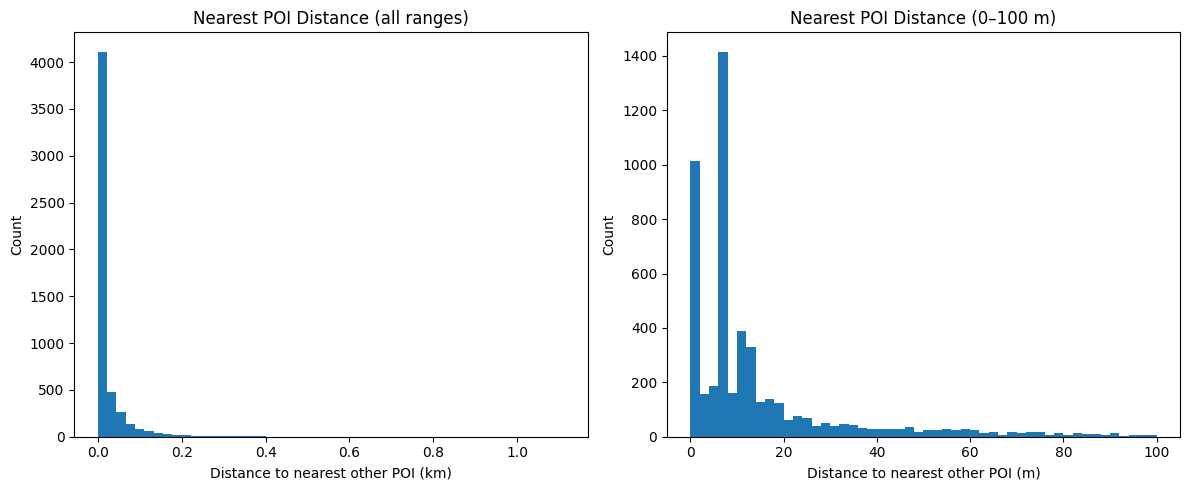

In [8]:
import numpy as np
import polars as pl
from sklearn.neighbors import BallTree
import matplotlib.pyplot as plt

# --- inputs: costa_expresses, foursquare_filtnew ---
# required columns: lat, lng, fsq_place_id (fsq_place_id can be null)

# Convert to numpy (radians)
c_lat = costa_expresses["lat"].to_numpy()
c_lng = costa_expresses["lng"].to_numpy()
c_ids = costa_expresses["fsq_place_id"].to_numpy()

f_lat = foursquare_filtnew["lat"].to_numpy()
f_lng = foursquare_filtnew["lng"].to_numpy()
f_ids = foursquare_filtnew["fsq_place_id"].to_numpy()

# radians
c_coords = np.deg2rad(np.c_[c_lat, c_lng])
f_coords = np.deg2rad(np.c_[f_lat, f_lng])

# Build BallTree on Foursquare POIs
tree = BallTree(f_coords, metric="haversine")

# Query k nearest to allow skipping self matches; pick a sensible k
k = min(10, len(f_coords)) if len(f_coords) > 0 else 1
dist_rad, idx = tree.query(c_coords, k=k, return_distance=True)

# Exclude matches with the same fsq_place_id (handle nulls safely)
c_ids_filled = np.where(c_ids == None, "", c_ids)  # noqa: E711
f_ids_filled = np.where(f_ids == None, "", f_ids)  # noqa: E711
neighbor_ids = f_ids_filled[idx]                   # (n, k)

# mask True where neighbor id != costa id (or costa id is empty)
mask = neighbor_ids != c_ids_filled[:, None]

# find first valid neighbor per row
has_valid = mask.any(axis=1)
first_valid_pos = np.where(has_valid, mask.argmax(axis=1), 0)

# pick distances for the first valid neighbor; NaN if none valid
row_idx = np.arange(len(c_coords))
nearest_dist_rad = np.where(
    has_valid,
    dist_rad[row_idx, first_valid_pos],
    np.nan
)

# convert to meters (Earth radius ~ 6,371,000 m)
nearest_dist_m = nearest_dist_rad * 6_371_000.0

# Assemble result DataFrame
nearest_df = pl.DataFrame({
    "fsq_place_id": c_ids,
    "nearest_poi_distance_m": nearest_dist_m
})

# Optional: join back to costa_expresses if you want full Costa rows + distance
# result_df = costa_expresses.join(nearest_df, on="fsq_place_id", how="left")

# --- Histogram ---
# Use km for readability
vals_km = nearest_df["nearest_poi_distance_m"].to_numpy() / 1000.0
vals_km = vals_km[~np.isnan(vals_km)]

# vals_km already computed above (nearest distances in km, no NaN)
vals_m = vals_km * 1000  # convert to meters

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Full distribution (in km)
axes[0].hist(vals_km, bins=50)
axes[0].set_xlabel("Distance to nearest other POI (km)")
axes[0].set_ylabel("Count")
axes[0].set_title("Nearest POI Distance (all ranges)")

# Zoomed histogram 0–100 m
mask = vals_m <= 100
axes[1].hist(vals_m[mask], bins=50, range=(0, 100))
axes[1].set_xlabel("Distance to nearest other POI (m)")
axes[1].set_ylabel("Count")
axes[1].set_title("Nearest POI Distance (0–100 m)")

plt.tight_layout()
plt.show()



In [9]:
# threshold in meters
threshold = 50  

# Costa rows with no POI within 50 m
costa_no_within_50 = costa_expresses.join(
    nearest_df.filter(
        (pl.col("nearest_poi_distance_m") >= threshold) | pl.col("nearest_poi_distance_m").is_null()
    ),
    on="fsq_place_id",
    how="inner"
)

costa_no_within_50


fsq_place_id,name,lat,lng,fsq_category_labels,address,locality,region,postcode,admin_region,post_town,date_created,date_refreshed,date_closed,tel,website,fsq_category_id,h3_11,level1_category_name,level2_category_name,level3_category_name,nearest_poi_distance_m
str,str,f64,f64,list[str],str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64
"""6af64ee96d2848e1837e93cd""","""Costa Express""",54.958701,-4.480579,"[""Dining and Drinking > Cafe, Coffee, and Tea House > Coffee Shop""]","""Creebridge Filling Station""","""Newton Stewart""","""Dumfries and Galloway""",null,null,"""Newton Stewart""","""2020-03-17""","""2023-04-23""",null,null,"""https://www.costa.co.uk""","""4bf58dd8d48988d1e0931735""","""8b1956a6cbadfff""","""Dining and Drinking""","""Cafe, Coffee, and Tea House""","""Coffee Shop""",82.349997
"""28df19f2f8ad4081834f3793""","""Costa Express""",56.175797,-3.027053,"[""Dining and Drinking > Cafe, Coffee, and Tea House > Coffee Shop""]","""106/110 Wellesley Rd""","""Leven""","""Fife""",null,"""Scotland""","""Leven""","""2020-03-17""","""2023-04-23""",null,null,"""https://www.costa.co.uk""","""4bf58dd8d48988d1e0931735""","""8b197202c7a5fff""","""Dining and Drinking""","""Cafe, Coffee, and Tea House""","""Coffee Shop""",60.971781
"""9d173f7f7043447d8194e5a6""","""Costa Express""",51.919094,-1.32478,"[""Dining and Drinking > Cafe, Coffee, and Tea House > Coffee Shop""]","""Hopcrofts Holt Service Statiom""","""Steeple Aston""","""Oxfordshire""",null,"""England""",null,"""2020-03-17""","""2023-04-23""",null,null,"""https://www.costa.co.uk""","""4bf58dd8d48988d1e0931735""","""8b195d5401b4fff""","""Dining and Drinking""","""Cafe, Coffee, and Tea House""","""Coffee Shop""",360.527
"""7c799aee82034e3a9b2e9477""","""Costa Express""",51.143867,-0.47165,"[""Dining and Drinking > Cafe, Coffee, and Tea House > Coffee Shop""]","""Park Parade""","""Cranleigh""","""Surrey""",null,"""England""","""Cranleigh""","""2020-03-17""","""2023-04-23""",null,null,"""https://www.costa.co.uk""","""4bf58dd8d48988d1e0931735""","""8b194a51d432fff""","""Dining and Drinking""","""Cafe, Coffee, and Tea House""","""Coffee Shop""",145.93413
"""1f1f81121e3f467665eb0454""","""Costa Express""",51.163856,0.307116,"[""Dining and Drinking > Cafe, Coffee, and Tea House > Coffee Shop""]","""Shipbourne Rd""","""Tonbridge""","""Kent""","""TN11 0QE""","""England""","""Tonbridge""","""2015-05-16""","""2023-04-23""",null,"""01892 533604""","""https://www.costa.co.uk""","""4bf58dd8d48988d1e0931735""","""8b194a88d81efff""","""Dining and Drinking""","""Cafe, Coffee, and Tea House""","""Coffee Shop""",184.783679
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""3b85176f12a1476a512bccd3""","""Costa Express""",55.7626,-4.85421,"[""Dining and Drinking > Cafe, Coffee, and Tea House > Coffee Shop""]","""Highland Fuels""","""Largs""","""North Ayrshire""",null,null,"""Largs""","""2020-03-17""","""2023-04-23""",null,null,"""https://www.costa.co.uk""","""4bf58dd8d48988d1e0931735""","""8b19092a6ca8fff""","""Dining and Drinking""","""Cafe, Coffee, and Tea House""","""Coffee Shop""",191.054827
"""b341c4b0424847007780c44d""","""Costa Express""",55.909805,-4.508475,"[""Dining and Drinking > Cafe, Coffee, and Tea House > Coffee Shop""]","""21 Greenock Rd""","""Greenock""","""Inverclyde""",null,null,"""Greenock""","""2020-03-17""","""2023-04-23""",null,null,"""https://www.costa.co.uk""","""4bf58dd8d48988d1e0931735""","""8b190932698efff""","""Dining and Drinking""","""Cafe, Coffee, and Tea House""","""Coffee Shop""",65.849253
"""9b531b49a5764eb330a8a80f""","""Costa Express""",57.11053,-2.094253,"[""Dining and Drinking > Cafe, Coffee, and Tea House > Coffee Shop""]","""Ellon Rd""","""Aberdeen""","""Aberdeen City""",null,null,"""Aberdeen""","""2016-11-08""","""2023-04-23""",null,"""0845 600 8545""","""https://www.costa.co.uk""","""4bf58dd8d48988d1e0931735""","""8b1976b95ca3fff""","""Dining and Drinking""","""Cafe, Coffee, and Tea House""","""Coffee Shop""",87.53659


In [10]:
import polars as pl
import geopandas as gpd


# Example: save Costa Expresses
polars_to_geoparquet(costa_no_within_50 ,"costa_expresses_no50.parquet")

# Example: save the 50m-filtered subset
# polars_to_geoparquet(costa_no_within_50, "costa_no_within_50.parquet")
costa_with_other

fsq_place_id
str
"""dabf66c14c87430b47c9de49"""
"""8c5298dd5e054b1c92974d93"""
"""ceef0eecb8ff44908f4efc56"""
"""6e684aef0a64476bc0851657"""
"""fbf03d4c5ebb491795a1663d"""
…
"""63d99c1e47d0478f333d9a85"""
"""c76927c3aa1947d90fc4da10"""
"""8af1f0ef6b9642b6a3a3f78b"""


In [11]:
#Medical Supply Store

#get rows which are level2 Medical Supply Store and 
medical_supply = foursquare_filtnew.filter(pl.col("level2_category_name") == "Medical Supply Store")

In [ ]:
import polars as pl

date_col = "date_created"  # <-- string column

# 1) Parse the string into a datetime column
dupes_with_date = (
    dupes_grouped.with_columns(
        pl.col(date_col)
          .str.strptime(pl.Datetime, strict=False, exact=False)
          .alias("date_ts")
    )
)

# 2) Pick the newest row per (lat,lng,fsq_category_id) group
keep_ids = (
    dupes_with_date
    .sort(["date_ts", "row_id"], descending=[True, False], nulls_last=True)
    .group_by(["lat_round", "lng_round", "fsq_category_id"])
    .agg(pl.first("row_id").alias("keep_row_id"))
    .select(pl.col("keep_row_id").alias("row_id"))
)

# 3) Rows to remove (older dupes)
rows_to_remove = dupes_grouped.join(keep_ids, on="row_id", how="anti")

# 4) Apply to the full dataset: keep newest only
df_dedup_latest = df.join(rows_to_remove.select("row_id"), on="row_id", how="anti")

# 5) Report how many places were removed
print(f"Removed {rows_to_remove.height} places by keeping only the most recent date_created per duplicate group.")

# Optional: see which rows were kept from the dupes
kept_from_dupes = dupes_grouped.join(keep_ids, on="row_id", how="inner")
kept_from_dupes


Removed 9894 places by keeping only the most recent date_created per duplicate group.


row_id,fsq_place_id,name,lat,lng,fsq_category_labels,address,locality,region,postcode,admin_region,post_town,date_created,date_refreshed,date_closed,tel,website,fsq_category_id,h3_11,lat_round,lng_round,name_norm,address_norm,tel_norm,website_norm,dup_count,match_fields
u32,str,str,f64,f64,list[str],str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,u32,str
5593,"""66d69f67f01e4c865e9d6c81""","""24/7 Locksmith Services in Nor…",51.52433,-0.174952,"[""Business and Professional Services > Locksmith""]","""18 Cooper House""","""London""","""Greater London""","""NW8 8NJ""","""England""","""London""","""2022-01-22""","""2022-01-22""",null,"""020 3667 3601""","""https://locksmiths.ltd/locksmi…","""52f2ab2ebcbc57f1066b8b1e""","""8b195da48782fff""",51.52433,-0.174952,"""24 7 locksmith services in nor…","""18 cooper house""","""020 3667 3601""","""locksmiths.ltd/locksmith-near-…",63,"""address, name, tel"""
8146,"""f0c2585fa0824ba53e6c6682""","""revistas.uned.es/index.php/REE…",51.428651,-0.349189,"[""Retail > Food and Beverage Retail > Health Food Store""]","""3 Oxford Rd""","""Teddington""","""Greater London""","""TW11 0QA""","""England""","""Teddington""","""2021-12-22""","""2021-12-22""",null,"""020 7412 8988""","""http://revistas.uned.es/index.…","""50aa9e744b90af0d42d5de0e""","""8b194ad9e106fff""",51.428651,-0.349189,"""revistas uned es index php ree…","""3 oxford rd""","""020 7412 8988""","""revistas.uned.es/index.php/ree…",33,"""address, tel"""
111495,"""7acf3556669d411e803cb8e7""","""Get Drivers for HP Envy 4500 p…",57.180641,-2.152922,"[""Business and Professional Services > Telecommunication Service"", ""Retail > Print Store""]","""North Dale Mabry Highway, Para…",null,null,null,null,null,"""2022-01-07""","""2022-01-07""",null,"""0844 608 1510""","""https://www.hpenvy4500.com/how…","""52f2ab2ebcbc57f1066b8b28""","""8b19768ccd8cfff""",57.180641,-2.152922,"""get drivers for hp envy 4500 p…","""north dale mabry highway param…","""0844 608 1510""","""hpenvy4500.com/how-to-fix-hp-e…",29,"""tel"""
108359,"""6fda33e83f0146ba0e48f255""","""Biglycan Elisa""",56.127508,-3.138937,"[""Sports and Recreation > Gym and Studio""]","""45-1 Ramsey Rd""","""Shirley""","""Derbyshire""",null,"""England""",null,"""2022-01-09""","""2022-01-09""",null,"""020 1754 8553""","""http://www.creative-diagnostic…","""4bf58dd8d48988d175941735""","""8b197201d260fff""",56.127508,-3.138937,"""biglycan elisa""","""45 1 ramsey rd""","""020 1754 8553""","""creative-diagnostics.com/symbo…",23,"""address, tel"""
54861,"""b5e0218083ca4652830ee5ec""","""Cell Cycle Assays""",56.127508,-3.138937,"[""Retail > Medical Supply Store""]","""45-1 Ramsey Rd""","""New York""","""Lincolnshire""",null,"""England""",null,"""2022-01-15""","""2022-01-15""",null,"""020 7048 3343""","""https://www.creative-bioarray.…","""58daa1558bbb0b01f18ec206""","""8b197201d260fff""",56.127508,-3.138937,"""cell cycle assays""","""45 1 ramsey rd""","""020 7048 3343""","""creative-bioarray.com/cell-cyc…",23,"""address, tel"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
766972,"""90ff78dea7d74c8eeeaa7794""","""Talmine Post Office""",58.521178,-4.425628,"[""Community and Government > Government Building > Post Office""]","""The Post Office, Sinnet""","""Skinnet""","""Sutherland""","""IV27 4YP""","""Scotland""","""Lairg""","""2010-05-18""","""2010-05-18""",null,"""01847 601200""",null,"""4bf58dd8d48988d172941735""","""8b192aaf01aafff""",58.521178,-4.425628,"""talmine post office""","""the post office sinnet""","""01847 601200""",null,2,"""name"""
61564,"""bdd2213fd76648dc084ed378""","""Post Office""",58.594557,-3.518841,"[""Community and Government > Government Building > Post Office""]","""Scottish Co-Op""","""Thurso""","""Highland""","""KW14 8ER""","""Scotland""","""Thurso""","""2013-09-10""","""2025-08-04""",null,"""0345 722 3344""","""http://www.postoffice.co.uk""","""4bf58dd8d48988d172941735""","""8b192871d8f3fff""",58.594557,-3.518841,"""post office""","""scotti

In [ ]:
defunct_retailers = pl.read_csv("../data/input_files/defunct_uk_retailers_wikipedia_full.csv")


# 1) Drop repeats on Brand column
defunct_retailers = defunct_retailers.unique(subset=["Brand"])

# 2) Remove anything in brackets () from Brand
defunct_retailers = defunct_retailers.with_columns(
    pl.col("Brand").str.replace(r"\s*\(.*?\)", "", literal=False)
)

#


In [18]:


# Assumptions:
# - defunct_retailers: pl.DataFrame with column "Brand"
# - foursquare_filtnew: pl.DataFrame with column "name"

# 1) Normalise brand names (case/whitespace) for matching
def make_key(col: pl.Expr) -> pl.Expr:
    return col.str.strip_chars().str.to_lowercase()

defunct = defunct_retailers.with_columns(
    brand_key = make_key(pl.col("Brand"))
)

fs = foursquare_filtnew.with_columns(
    brand_key = make_key(pl.col("name"))
)

# 2) Rows in FS that match a defunct brand (to be removed)
removed = fs.join(defunct.select("brand_key").unique(), on="brand_key", how="inner")

# 3) Count how many FS POIs removed per defunct brand
removed_counts = (
    removed
    .group_by("brand_key")
    .len()
    .rename({"len": "removed_poi_count"})
)

# 4) Add the counts back to defunct_retailers (0 if none)
defunct_with_counts = (
    defunct
    .join(removed_counts, on="brand_key", how="left")
    .with_columns(pl.col("removed_poi_count").fill_null(0).cast(pl.Int64))
    .drop("brand_key")
)

# 5) The filtered FS dataframe (with defunct brands removed)
foursquare_filtered = fs.join(
    defunct.select("brand_key").unique(),
    on="brand_key",
    how="anti"
).drop("brand_key")


In [ ]:
defunct_with_counts = defunct_with_counts.sort("removed_poi_count", descending=True)
defunct_with_counts.head(10)

In [38]:
import polars as pl
import geopandas as gpd
import re

# -----------------------------
# Assumptions from earlier:
# - defunct_retailers: pl.DataFrame with "Brand"
# - foursquare_filtnew: pl.DataFrame with "name", "lat", "lng"
# -----------------------------

# Helper to normalize for matching
def make_key(col: pl.Expr) -> pl.Expr:
    return col.str.strip_chars().str.to_lowercase()

# 0) (Optional) Clean + dedupe defunct list like before
defunct_retailers = (
    defunct_retailers
    .unique(subset=["Brand"])
    .with_columns(
        # remove bracketed suffixes e.g. "Woolworths (UK)" -> "Woolworths"
        pl.col("Brand").str.replace(r"\s*\(.*?\)", "", literal=False)
    )
)

# 1) Build normalized keys
defunct = defunct_retailers.with_columns(brand_key = make_key(pl.col("Brand")))
fs = foursquare_filtnew.with_columns(brand_key = make_key(pl.col("name")))

# 2) Find rows to remove (the removed POIs)
removed = fs.join(defunct.select("brand_key").unique(), on="brand_key", how="inner")

# 3) Top 10 brands by number of removed POIs
removed_counts = (
    removed
    .group_by("brand_key")
    .len()
    .rename({"len": "removed_poi_count"})
    .sort("removed_poi_count", descending=True)
)

top10_keys = removed_counts.select("brand_key").head(10)

# 4) Keep only removed POIs for those top 10 brands
top10_removed = removed.join(top10_keys, on="brand_key", how="inner")

# 5) Add human-readable brand back in
defunct_lookup = defunct.select(["brand_key", "Brand"]).unique()
top10_removed = (
    top10_removed
    .join(defunct_lookup, on="brand_key", how="left")
    .rename({"Brand": "defunct_brand"})
)

# 6) Ensure lat/lng present
top10_removed = top10_removed.filter(
    pl.all_horizontal(
        pl.col("lat").is_not_null(),
        pl.col("lng").is_not_null()
    )
)

# 7) Write one GeoParquet per brand of removed locations
out_dir = Path("defunct_removed_top10")
out_dir.mkdir(parents=True, exist_ok=True)

# Partition by brand
parts = top10_removed.partition_by("defunct_brand", as_dict=False)

for i, df in enumerate(parts, start=1):
    pdf = df.to_pandas()
    gdf = gpd.GeoDataFrame(
        pdf,
        geometry=gpd.points_from_xy(pdf["lng"], pdf["lat"]),
        crs="EPSG:4326"
    )
    fname = out_dir / f"topbrand{i}.geo.parquet"
    gdf.to_parquet(fname)
    print(f"Wrote {fname.name} ({len(gdf)} points)")


Wrote topbrand1.geo.parquet (418 points)
Wrote topbrand2.geo.parquet (933 points)
Wrote topbrand3.geo.parquet (113 points)
Wrote topbrand4.geo.parquet (66 points)
Wrote topbrand5.geo.parquet (119 points)
Wrote topbrand6.geo.parquet (64 points)
Wrote topbrand7.geo.parquet (165 points)
Wrote topbrand8.geo.parquet (64 points)
Wrote topbrand9.geo.parquet (63 points)
Wrote topbrand10.geo.parquet (41 points)


In [31]:
#search for woolworths in foursquare_filtered
woolworths_fs = foursquare_filtered.filter(pl.col("name").str.contains("woolworth"))

In [32]:
woolworths_fs

fsq_place_id,name,lat,lng,address,locality,region,postcode,admin_region,post_town,po_box,country,date_created,date_refreshed,date_closed,tel,website,fsq_category_id,fsq_category_labels,h3_11
str,str,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,list[str],str
"""4b59c5acf964a520439728e3""","""woolworths social club""",53.603172,-2.176291,null,null,null,null,null,null,null,"""GB""","""2010-01-22""","""2024-05-02""",null,null,null,"""52e81612bcbc57f1066b7a33""","[""Community and Government > Social Club""]","""8b19424f0335fff"""


Processing ways: 100%|██████████| 33173004/33173004 [05:05<00:00, 108584.30it/s]


Saved 7776570 road segments


In [9]:
foursquare_filtnew

fsq_place_id,name,lat,lng,fsq_category_labels,address,locality,region,postcode,admin_region,post_town,date_created,date_refreshed,date_closed,tel,website,fsq_category_id,h3_11,level1_category_name,level2_category_name,level3_category_name
str,str,f64,f64,list[str],str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""a4e7cb3d9091480ffe082b59""","""With Love""",53.575283,-1.067467,"[""Retail > Gift Store""]","""Top Rd""","""Barnby Dun""","""South Yorkshire""","""DN3 1DB""","""England""","""Doncaster""","""2010-05-22""","""2025-06-05""",null,"""01302 888838""",null,"""4bf58dd8d48988d128951735""","""8b194216d24cfff""","""Retail""","""Gift Store""",null
"""067d069eba7746b643fd8442""","""Baltasound Post Office""",60.757837,-0.860013,"[""Community and Government > Government Building > Post Office""]","""Baltasound, Unst""","""Brae""","""Shetland Islands""","""ZE2 9DP""","""Scotland""","""Shetland""","""2010-05-19""","""2010-05-19""",null,"""01957 711655""",null,"""4bf58dd8d48988d172941735""","""8b09a096b46bfff""","""Community and Government""","""Government Building""","""Post Office"""
"""f564030e30ba454901415cc3""","""G M N""",51.857615,-2.216234,"[""Dining and Drinking > Restaurant > American Restaurant""]","""Eastbrook Rd""","""Gloucester""","""Gloucestershire""","""GL4 3DB""","""England""","""Gloucester""","""2013-07-04""","""2025-06-05""",null,"""01452 384055""",null,"""4bf58dd8d48988d14e941735""","""8b19588c5628fff""","""Dining and Drinking""","""Restaurant""","""American Restaurant"""
"""4b77e579f964a520ffad2ee3""","""Jacobs Wells Baths""",51.451658,-2.6084,"[""Community and Government > Community Center"", ""Sports and Recreation > Gym and Studio > Dance Studio""]","""Jacobs Wells Road""","""Bristol""","""Bristol""",null,"""England""",null,"""2010-02-14""","""2025-07-16""",null,null,"""http://theislandbristol.com/sp…","""52e81612bcbc57f1066b7a34""","""8b195876cd58fff""","""Community and Government""","""Community Center""",null
"""4ee5eb164690f88941db8b09""","""Post Office Overdown Road""",51.469848,-1.04434,"[""Community and Government > Government Building > Post Office""]","""Overdown Road""","""Reading""","""Berkshire""",null,"""England""",null,"""2011-12-12""","""2020-10-22""",null,"""0118 956 6541""","""http://www.postoffice.co.uk""","""4bf58dd8d48988d172941735""","""8b195d749813fff""","""Community and Government""","""Government Building""","""Post Office"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""e7cb188b0aa1487517fbb385""","""Hogg Engineering""",54.985799,-1.562704,"[""Community and Government > Government Building > Post Office""]","""Benfield Business Park, Benfie…","""Newcastle upon Tyne""","""Tyne and Wear""","""NE6 4NQ""","""England""","""Newcastle Upon Tyne""","""2014-08-10""","""2025-06-07""",null,"""0191 276 9940""","""http://www.hoggpackaging.co.uk""","""4bf58dd8d48988d172941735""","""8b1973351573fff""","""Community and Government""","""Government Building""","""Post Office"""
"""9812719dc70e400f7dd29f36""","""Whitney Woods""",53.695981,-2.274167,"[""Business and Professional Services > Advertising Agency"", ""Retail > Print Store""]","""Victoria Works, Hill End Lane""","""Rossendale""","""Lancashire""","""BB4 7AG""","""England""","""Rossendale""","""2010-06-05""","""2010-06-05""",null,"""01706 210538""","""http://www.whitneywoods.co.uk""","""52f2ab2ebcbc57f1066b8b28""","""8b19424a340efff""","""Retail""","""Print Store""",null
"""6b7a79a857aa453d02193cf3""","""Russell Hanson - the London Ha…",51.423634,-0.194898,"[""Business and Professional Services > Real Estate Service > Real Estate Agency""]","""1 St Andrews Close""","""London""","""Greater London""","""SW19 8NJ""","""England""","""London""","""2013-01-13""","""2013-01-13""",null,"""07973 146693""","""http://www.russellhanson.co.uk""","""5032885091d4c4b30a586d66""","""8b194adab9a6fff""","""Business and Professional Serv…","""Real Estate Service""","""Real Estate Agency"""


Roads loaded: 7776570
Roads loaded: 7776570


Processing POIs: 100%|██████████| 1503284/1503284 [17:13:01<00:00, 24.25rows/s, rows 1,500,000–1,503,284]   


Summary:
 Original POIs: 1503284
 Further than 200m: 1884


In [6]:
foursquare_far

fsq_place_id,name,lat,lng,fsq_category_labels,address,locality,region,postcode,admin_region,post_town,date_created,date_refreshed,date_closed,tel,website,fsq_category_id,h3_11,level1_category_name,level2_category_name,level3_category_name,index_right,highway,dist_to_road
str,str,f64,f64,list[str],str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,f64
"""4c556090728920a1e9694e84""","""Next""",53.027494,-2.175777,"[""Retail > Fashion Retail > Clothing Store""]","""Quadrant Road""","""Stoke-on-Trent""","""Staffordshire""","""ST1 1PS""","""England""",null,"""2010-08-01""","""2025-07-04""",null,"""0333 005 5465""","""http://www.next.co.uk""","""4bf58dd8d48988d103951735""","""8b195cc2e6cafff""","""Retail""","""Fashion Retail""","""Clothing Store""",3045992,"""unclassified""",77.447354
"""64de03029b24a42b18a050cc""","""Blompy The Busking Banjo Stage""",51.868702,-3.174224,"[""Arts and Entertainment > Performing Arts Venue > Music Venue""]",null,"""Crickhowell""","""Wales""","""NP8""",null,null,"""2023-08-17""","""2023-08-17""",null,null,null,"""4bf58dd8d48988d1e5931735""","""8b1958435d34fff""","""Arts and Entertainment""","""Performing Arts Venue""","""Music Venue""",2187770,"""service""",62.468325
"""4d95ed2eaf3d236a5c0bfdc6""","""The Crystal Palace""",51.712144,-0.558966,"[""Dining and Drinking > Bar > Pub""]",null,null,null,null,null,null,"""2011-04-01""","""2023-02-20""",null,null,null,"""4bf58dd8d48988d11b941735""","""8b195da84081fff""","""Dining and Drinking""","""Bar""","""Pub""",21085,"""unclassified""",211.154507
"""02e2236d8ea84b542a6f8c54""","""Penketh Parish Swimming Pool &…",53.379953,-2.65016,"[""Sports and Recreation > Gym and Studio""]","""Honiton Way""","""Penketh""","""Cheshire""","""WA5 2EY""","""England""","""Warrington""","""2010-05-21""","""2025-08-01""",null,"""01925 724515""","""http://www.penkethparishcounci…","""4bf58dd8d48988d175941735""","""8b1951aaa033fff""","""Sports and Recreation""","""Gym and Studio""",null,653526,"""track""",72.955993
"""8bf89fa898f84e8403da199a""","""Wheel Seal""",54.498321,-6.737701,"[""Retail > Food and Beverage Retail > Fruit and Vegetable Store""]","""45 Killyneill Rd""","""Dungannon""","""Tyrone""","""BT71 6LL""","""Northern Ireland""","""Dungannon""","""2016-05-11""","""2016-05-11""",null,"""028 8772 5801""",null,"""52f2ab2ebcbc57f1066b8b1c""","""8b182524e4e2fff""","""Retail""","""Food and Beverage Retail""","""Fruit and Vegetable Store""",2625758,"""unclassified""",187.476836
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""4f22f9e2e4b0e120801ceaa5""","""Premier Convenience Store""",53.589056,-2.705059,"[""Retail > Convenience Store""]","""Dingle Rd, Lancashire WN8""",null,"""Greater Manchester""",null,"""England""",null,"""2012-01-27""","""2017-10-23""",null,null,"""http://www.premier-stores.co.u…","""4d954b0ea243a5684a65b473""","""8b19518cd36dfff""","""Retail""","""Convenience Store""",null,4546769,"""service""",244.266379
"""91f1d922a0f042f63ee7cfa7""","""BSW Timber""",54.925574,-2.977154,"[""Retail""]","""Carlisle Sawmills, Cargo""","""Carlisle""","""Cumbria""","""CA6 4BA""","""England""","""Carlisle""","""2011-08-15""","""2025-08-01""",null,"""01228 674221""","""http://www.bsw.co.uk""","""4d4b7105d754a06378d81259""","""8b1955d82902fff""","""Retail""",null,null,3694142,"""service""",72.94977
"""6aef72db56664002b01ce6da""","""Notley Sports Centre""",51.866001,0.550183,"[""Sports and Recreation > Gym and Studio""]","""Notley Rd""","""Braintree""","""Essex""","""CM7 1WX""","""England""","""Braintree""","""2011-10-30""","""2025-06-05""",null,"""01376 323873""",null,"""4bf58dd8d48988d175941735""","""8b194e01374efff""","""Sports and Recreation""","""Gym and Studio""",null,3634618,"""service""",50.243723
